In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import numpy as np
import joblib

from scipy.stats import rankdata

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

In [ ]:
# ==========================================
# STEP 2: LOAD TRAINED MODEL & PREPROCESSING OBJECTS
# ==========================================

import joblib

base_path = "/content/drive/MyDrive/RE2"

# trained model
model = joblib.load(base_path + "/best_models/Cost_XGB_Cost.pkl")

# training imputer
imputer = joblib.load(base_path + "/checkpoints/imputer.pkl")

# training scaler
scaler = joblib.load(base_path + "/checkpoints/scaler.pkl")

print("Model Loaded Successfully")
print("Imputer Loaded Successfully")
print("Scaler Loaded Successfully")

Model Loaded Successfully
Imputer Loaded Successfully
Scaler Loaded Successfully


In [ ]:
# ==========================================
# STEP 1: LOAD EXTERNAL DATASET
# ==========================================

import pandas as pd

external_path = "/content/drive/MyDrive/exvall/sepsis_icu_synthetic.csv"

df_ext = pd.read_csv(external_path)

print("External Dataset Shape:", df_ext.shape)
df_ext.head()

External Dataset Shape: (5000, 77)


,subject_id,age,gender,weight_kg,height_cm,bmi,ethnicity,insurance,hr_mean,hr_max,...,apache_iv,qsofa,sirs_criteria,gcs_total,icu_los_hours,hospital_admit_source,icu_admit_time_hour,day_of_week,readmission_30day,sepsis_label
0,37464,72,M,99.5,160.6,38.6,Black,Medicare,83.0,98.7,...,47.9,2,1,12,27.0,OR,15,2,1,1
1,34024,62,M,101.2,164.5,37.4,Other,Private,97.5,105.8,...,35.0,1,1,6,21.5,Transfer,21,2,0,0
2,65291,74,M,64.0,167.2,22.9,White,Private,100.6,105.8,...,29.0,1,1,11,46.7,ED,19,6,0,0
3,79118,87,M,75.1,180.5,23.0,White,Medicare,95.5,114.7,...,35.6,1,1,7,1.7,ED,8,2,0,0
4,34897,61,M,52.5,158.4,NaN,Hispanic,Private,86.7,106.7,...,34.6,1,1,8,64.0,Transfer,9,2,0,0


In [ ]:
# ==========================================
# MAP EXTERNAL DATASET TO TRAINING FEATURES
# ==========================================

import numpy as np
import pandas as pd

# Rename columns

rename_dict = {

    # Demographics
    "age":"Age",
    "gender":"Gender",

    # Vitals
    "hr_mean":"HR",
    "spo2_mean":"O2Sat",
    "sbp_mean":"SBP",
    "map_mean":"MAP",
    "respiratory_rate_mean":"Resp",

    # ICU
    "icu_los_hours":"ICULOS",

}

df_ext = df_ext.rename(columns=rename_dict)

# Gender Encoding

df_ext["Gender"] = df_ext["Gender"].map({
    "M":1,
    "F":0,
    "Male":1,
    "Female":0
})
print(df_ext.columns.tolist())

['subject_id', 'Age', 'Gender', 'weight_kg', 'height_cm', 'bmi', 'ethnicity', 'insurance', 'HR', 'hr_max', 'hr_min', 'hr_std', 'SBP', 'sbp_max', 'sbp_min', 'sbp_std', 'dbp_mean', 'dbp_max', 'dbp_min', 'dbp_std', 'MAP', 'temp_celsius_mean', 'temp_celsius_max', 'temp_celsius_min', 'temp_celsius_std', 'O2Sat', 'spo2_min', 'spo2_max', 'spo2_std', 'Resp', 'respiratory_rate_max', 'respiratory_rate_min', 'respiratory_rate_std', 'wbc', 'lactate_mmol', 'creatinine', 'platelet_count', 'bilirubin_total', 'glucose', 'ph_arterial', 'pao2_fio2_ratio', 'inr', 'sodium', 'potassium', 'chloride', 'bicarbonate', 'hematocrit', 'hemoglobin', 'diabetes', 'hypertension', 'chf', 'copd', 'chronic_kidney_disease', 'liver_disease', 'immunosuppression', 'cad', 'atrial_fibrillation', 'cancer_active', 'vasopressors_flag', 'mechanical_ventilation', 'fio2_percent', 'antibiotics_24h', 'fluids_ml_24h', 'sedation_score', 'vasopressor_dose_mcg_kg_min', 'insulin_infusion_flag', 'sofa_score', 'apache_iv', 'qsofa', 'sirs_cr

In [ ]:
original_features = [

'Hour',
'HR',
'O2Sat',
'SBP',
'MAP',
'Resp',
'Age',
'Gender',
'HospAdmTime',
'ICULOS',

'HR_missing',
'O2Sat_missing',
'Temp_missing',
'SBP_missing',
'MAP_missing',
'DBP_missing',
'Resp_missing',
'EtCO2_missing',
'BaseExcess_missing',
'HCO3_missing',
'FiO2_missing',
'pH_missing',
'PaCO2_missing',
'SaO2_missing',
'AST_missing',
'BUN_missing',
'Alkalinephos_missing',
'Calcium_missing',
'Chloride_missing',
'Creatinine_missing',
'Bilirubin_direct_missing',
'Glucose_missing',
'Lactate_missing',
'Magnesium_missing',
'Phosphate_missing',
'Potassium_missing',
'Bilirubin_total_missing',
'TroponinI_missing',
'Hct_missing',
'Hgb_missing',
'PTT_missing',
'WBC_missing',
'Fibrinogen_missing',
'Platelets_missing',
'Unit1_missing',
'Unit2_missing'

]

for col in original_features:

    if col not in df_ext.columns:

        df_ext[col]=np.nan

In [ ]:
#Missing Indicators)
base_features = [

'HR','O2Sat','Temp','SBP','MAP','DBP','Resp','EtCO2',
'BaseExcess','HCO3','FiO2','pH','PaCO2','SaO2',
'AST','BUN','Alkalinephos','Calcium','Chloride',
'Creatinine','Bilirubin_direct','Glucose',
'Lactate','Magnesium','Phosphate','Potassium',
'Bilirubin_total','TroponinI','Hct','Hgb',
'PTT','WBC','Fibrinogen','Platelets','Unit1','Unit2'

]

for col in base_features:

    if col in df_ext.columns:

        df_ext[col+"_missing"]=df_ext[col].isna().astype(int)

    else:

        df_ext[col+"_missing"]=1

In [ ]:
#(Exactly 46 features select
X_ext = df_ext[original_features].copy()

print(X_ext.shape)

(5000, 46)


In [ ]:
#Imputer
import joblib

imputer = joblib.load("/content/drive/MyDrive/RE2/checkpoints/imputer.pkl")

X_ext = pd.DataFrame(

    imputer.transform(X_ext),

    columns=original_features

)

In [ ]:
#Log Transformation
import numpy as np

skew_cols = ['MAP','BUN','Creatinine','Glucose','WBC','Platelets']

for col in skew_cols:
    if col in X_ext.columns:
        X_ext[col] = np.log1p(X_ext[col])

print("Log Transformation Done")

Log Transformation Done


In [ ]:
#Copula Features
from scipy.stats import rankdata

def copula_transform(x):
    return rankdata(x) / (len(x) + 1)

copula_cols = ['HR','MAP','SBP','O2Sat','Resp']

for col in copula_cols:
    if col in X_ext.columns:
        X_ext[col + "_copula"] = copula_transform(X_ext[col])

print("Copula Features Added")
print(X_ext.shape)

Copula Features Added
(5000, 51)


In [ ]:
#Load Scaler & Scale
import joblib
import pandas as pd

scaler = joblib.load("/content/drive/MyDrive/RE2/checkpoints/scaler.pkl")

X_ext_scaled = scaler.transform(X_ext)

X_ext_scaled = pd.DataFrame(
    X_ext_scaled,
    columns=X_ext.columns
)

print("Scaling Done")

Scaling Done


In [ ]:
#Load Best Model
model = joblib.load(
    "/content/drive/MyDrive/RE2/best_models/Cost_XGB_Cost.pkl"
)

print("Best Cost_XGB Model Loaded")

Best Cost_XGB Model Loaded


In [ ]:
#Prediction

best_threshold = 0.5

y_prob = model.predict_proba(X_ext_scaled)[:,1]

y_pred = (y_prob >= best_threshold).astype(int)

print(y_pred[:10])

[0 0 0 0 1 0 0 0 1 1]


In [ ]:
#Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("Accuracy :", accuracy_score(y_external, y_pred))
print("Precision:", precision_score(y_external, y_pred))
print("Recall   :", recall_score(y_external, y_pred))
print("F1 Score :", f1_score(y_external, y_pred))
print("ROC AUC  :", roc_auc_score(y_external, y_prob))

Accuracy : 0.7464
Precision: 0.24507874015748032
Recall   : 0.332
F1 Score : 0.28199320498301245
ROC AUC  : 0.741099137254902


In [ ]:
#Classification Report
from sklearn.metrics import classification_report

print(classification_report(y_external, y_pred))

              precision    recall  f1-score   support

           0       0.87      0.82      0.85      4250
           1       0.25      0.33      0.28       750

    accuracy                           0.75      5000
   macro avg       0.56      0.58      0.56      5000
weighted avg       0.78      0.75      0.76      5000



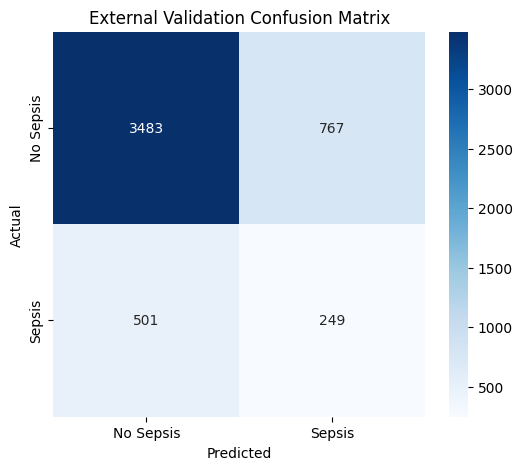

In [ ]:
#Confusion Matrix
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_external, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Sepsis','Sepsis'],
    yticklabels=['No Sepsis','Sepsis']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("External Validation Confusion Matrix")

plt.savefig(
    base_path + "/External_Confusion_Matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

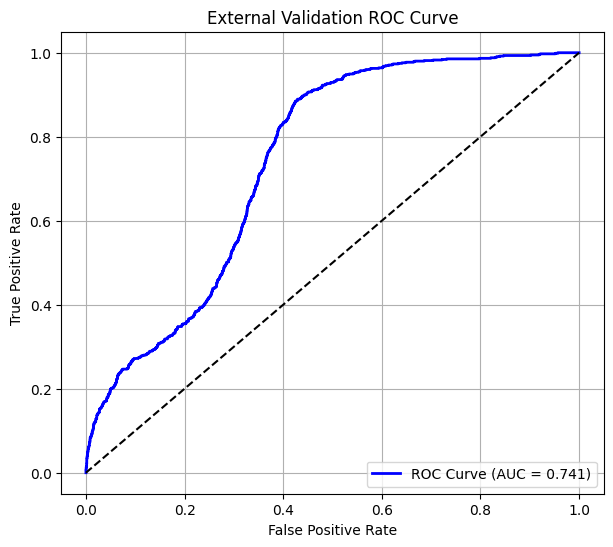

In [ ]:
#ROC Curve
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

fpr, tpr, _ = roc_curve(y_external, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7,6))

plt.plot(fpr, tpr,
         color='blue',
         lw=2,
         label=f'ROC Curve (AUC = {roc_auc:.3f})')

plt.plot([0,1],[0,1],'k--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("External Validation ROC Curve")

plt.legend(loc="lower right")
plt.grid(True)

plt.savefig(
    base_path + "/External_ROC_Curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

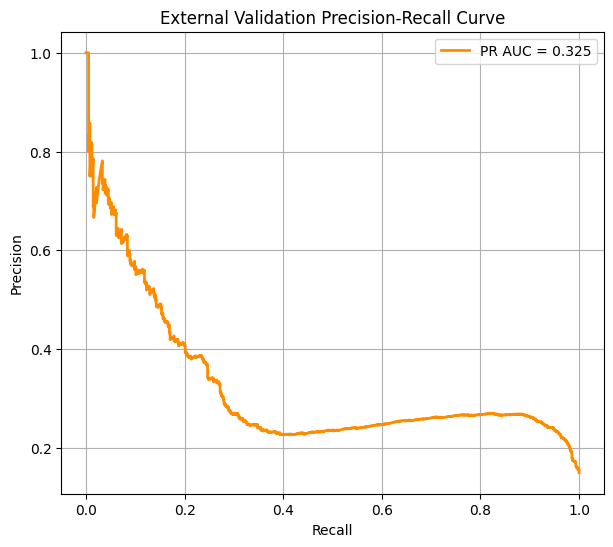

PR AUC = 0.32517419417720606


In [ ]:
#Precision-Recall Curve
from sklearn.metrics import precision_recall_curve

precision, recall, _ = precision_recall_curve(
    y_external,
    y_prob
)

pr_auc = auc(recall, precision)

plt.figure(figsize=(7,6))

plt.plot(
    recall,
    precision,
    color='darkorange',
    lw=2,
    label=f'PR AUC = {pr_auc:.3f}'
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("External Validation Precision-Recall Curve")

plt.legend()
plt.grid(True)

plt.savefig(
    base_path + "/External_PR_Curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("PR AUC =", pr_auc)

In [ ]:
#95% Bootstrap Confidence Intervals
from sklearn.utils import resample
from sklearn.metrics import roc_auc_score

boot_scores = []

n_iterations = 1000

for i in range(n_iterations):

    indices = resample(
        np.arange(len(y_external)),
        replace=True
    )

    if len(np.unique(y_external.iloc[indices])) < 2:
        continue

    score = roc_auc_score(
        y_external.iloc[indices],
        y_prob[indices]
    )

    boot_scores.append(score)

lower = np.percentile(boot_scores,2.5)
upper = np.percentile(boot_scores,97.5)

print("ROC AUC =", roc_auc_score(y_external,y_prob))
print("95% CI =",lower,"-",upper)

ROC AUC = 0.741099137254902
95% CI = 0.7254171771792587 - 0.7557942503208154


In [ ]:
#External Validation Summary Table
results = pd.DataFrame({

    "Metric":[
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC AUC",
        "PR AUC"
    ],

    "Value":[
        accuracy_score(y_external,y_pred),
        precision_score(y_external,y_pred),
        recall_score(y_external,y_pred),
        f1_score(y_external,y_pred),
        roc_auc_score(y_external,y_prob),
        pr_auc
    ]

})

print(results)

results.to_csv(
    "/content/drive/MyDrive/RE2/tables/External_Validation_Results.csv",
    index=False
)

      Metric     Value
0   Accuracy  0.746400
1  Precision  0.245079
2     Recall  0.332000
3   F1 Score  0.281993
4    ROC AUC  0.741099
5     PR AUC  0.325174


In [ ]:
#Threshold Analysis
thresholds = [0.3,0.4,0.5,0.6,0.7,0.8]

rows=[]

for th in thresholds:

    pred=(y_prob>=th).astype(int)

    rows.append({

        "Threshold":th,

        "Accuracy":accuracy_score(y_external,pred),

        "Precision":precision_score(y_external,pred,zero_division=0),

        "Recall":recall_score(y_external,pred,zero_division=0),

        "F1":f1_score(y_external,pred,zero_division=0)

    })

threshold_df=pd.DataFrame(rows)

print(threshold_df)

   Threshold  Accuracy  Precision    Recall        F1
0        0.3    0.6582   0.259408  0.689333  0.376960
1        0.4    0.6854   0.236387  0.492000  0.319342
2        0.5    0.7464   0.245079  0.332000  0.281993
3        0.6    0.8336   0.393782  0.202667  0.267606
4        0.7    0.8538   0.711111  0.042667  0.080503
5        0.8    0.8502   1.000000  0.001333  0.002663
